# TP 3 — Arbres de décision sur Adult

In [1]:
import sys; sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

import utils
utils.style()

GRAINE = 42

Mục tiêu cốt lõi của toàn bộ bài tập này là: Làm sao để xây dựng một mô hình Cây quyết định (Decision Tree) dự đoán thu nhập tốt nhất có thể, tránh việc mô hình bị "học vẹt" (overfitting). Ở đây, mô hình đang đưa ra dự đoán (phân loại) mức thu nhập của một người

## Exercice 1. Changement de jeu de données

### 1.1 Découvrir Adult

In [2]:
df = utils.load_adult()
df.head()

,age,workclass,education,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,27,Private,Assoc-acdm,Never-married,Sales,Not-in-family,White,Male,0,0,52,United-States,0
1,32,Private,5th-6th,Separated,Farming-fishing,Other-relative,White,Male,0,0,60,Mexico,0
2,40,Private,HS-grad,Divorced,Other-service,Unmarried,White,Female,0,0,36,United-States,0
3,43,Private,HS-grad,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,44,United-States,0
4,40,Private,Assoc-acdm,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,40,United-States,0


In [3]:
df.shape

(10000, 13)

In [4]:
# Lọc các cột số (numeric) và cột phân loại (categorical/object)
num_cols = df.select_dtypes(include=['number']).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

print(f"Số lượng biến numériques (định lượng): {len(num_cols)}")
print(f"Danh sách: {list(num_cols)}")

print(f"\nSố lượng biến catégorielles (định tính): {len(cat_cols)}")
print(f"Danh sách: {list(cat_cols)}")

Số lượng biến numériques (định lượng): 5
Danh sách: ['age', 'capital-gain', 'capital-loss', 'hours-per-week', 'income']

Số lượng biến catégorielles (định tính): 8
Danh sách: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


### 1.2 Données brutes

In [5]:
X_brut = df.drop(columns="income")
y = df["income"]

DecisionTreeClassifier().fit(X_brut, y)     # que se passe-t-il ?

ValueError: could not convert string to float: 'Private'

Có thể thấy income là biến định lượng và cái biến này, một trong những vấn đề của việc có 2 biến định lượng và biến định tính đó là 2 cái này nó ko có cùng échelle do đó rất khó để tính được do một cái là số và 1 cái là chữ. Do đó thông thường có 2 cách để giải quyết các bước đầu của xử lý dữ liệu đó là 1 là làm việc trước với các biến định lượng sau đó dùng các kết quả đó rồi phân tích trên các biến định lượng. Cách 2 đó là encodage và thường sẽ biến nó về dưới dạng binary để có dưới dạng số 0 và 1. Tuy nhiên ở cách này thì phải nhớ là chúng ta đang có disquantif complex do đó việc cần thiết là phải biến mọi thứ về cùng 1 échelle nếu ko thì sẽ xuất hiện dispension rồi variance sẽ rất lớn

### 1.3 Encodage

In [6]:
X, y, noms = utils.adult_xy()
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, random_state=GRAINE, stratify=y)
print(f"{X.shape[0]} observations, {X.shape[1]} variables encodées")

10000 observations, 12 variables encodées


## Exercice 2 — Lecture d’un arbre

### 2.1 Effet de la profondeur

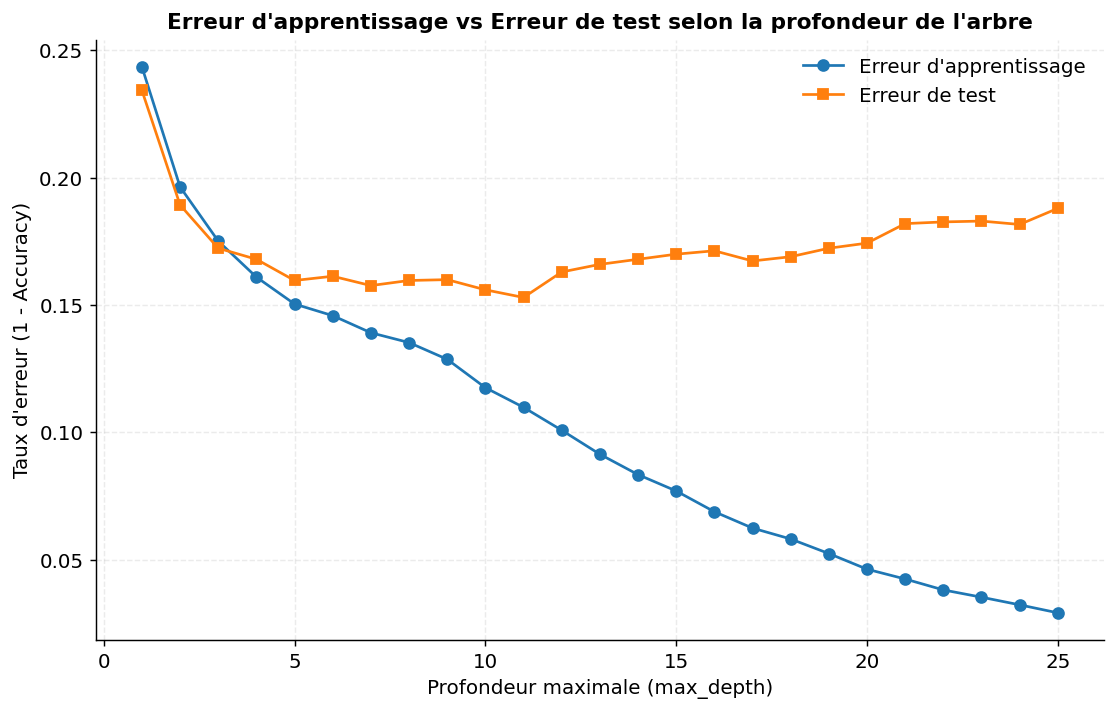

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 0. Préparation : Encodage des variables catégorielles et séparation Train/Test
X = pd.get_dummies(df.drop(columns='income'), drop_first=True)
y = df['income']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Listes pour stocker les erreurs
train_errors = []
test_errors = []
depths = range(1, 26)

# 1. Boucle sur les profondeurs de 1 à 25
for depth in depths:
  # Initialisation et entraînement de l'arbre
  clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
  clf.fit(X_train, y_train)

  # Calcul du taux d'erreur (1 - accuracy)
  train_err = 1 - accuracy_score(y_train, clf.predict(X_train))
  test_err = 1 - accuracy_score(y_test, clf.predict(X_test))

  train_errors.append(train_err)
  test_errors.append(test_err)

# 2. Tracé des courbes d'erreur
plt.figure(figsize=(10, 6))
plt.plot(depths, train_errors, label="Erreur d'apprentissage", marker='o')
plt.plot(depths, test_errors, label='Erreur de test', marker='s')
plt.xlabel('Profondeur maximale (max_depth)')
plt.ylabel("Taux d'erreur (1 - Accuracy)")
plt.title("Erreur d'apprentissage vs Erreur de test selon la profondeur de l'arbre")
plt.legend()
plt.grid(True)
plt.show()

### 2.2 Lire l’arbre

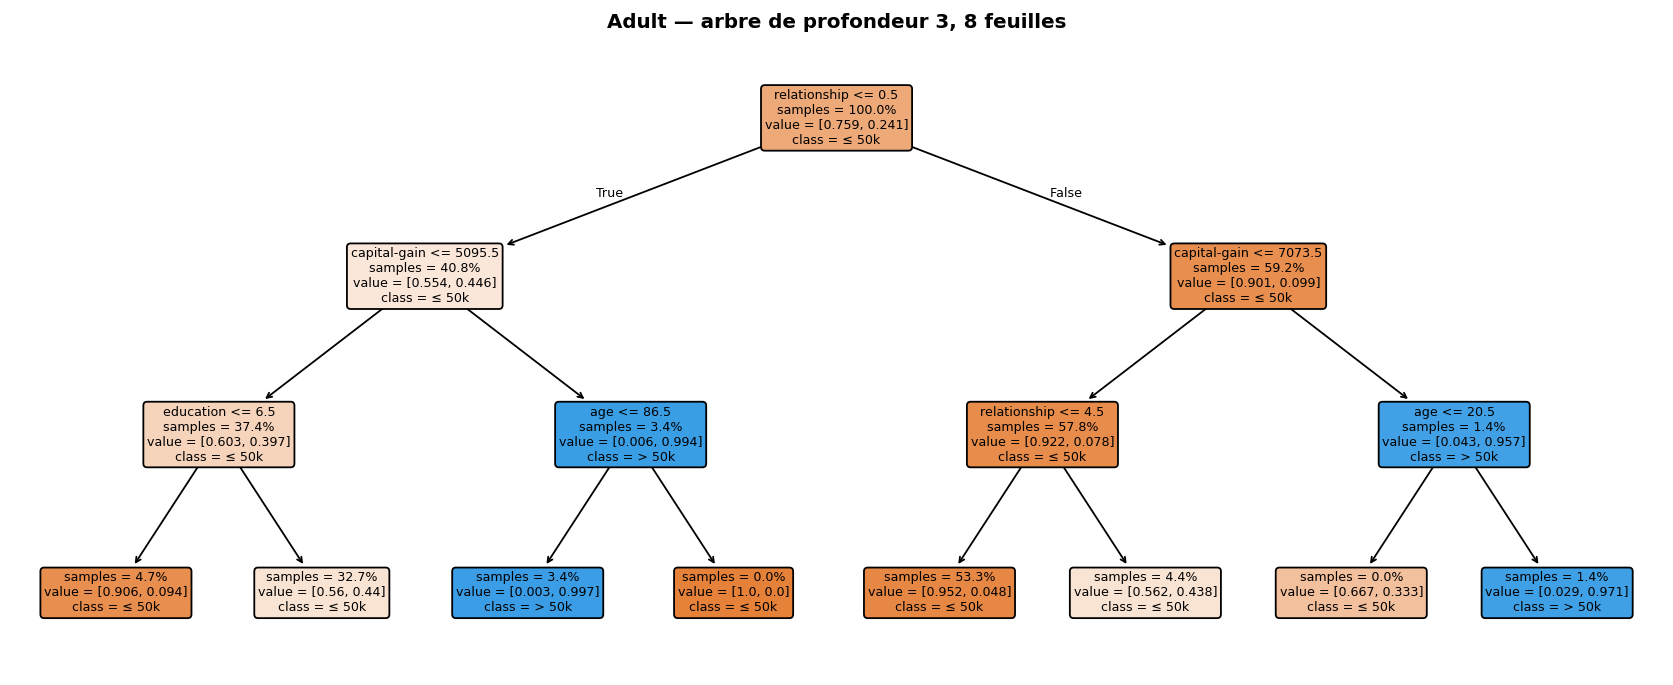

In [8]:
fig = utils.plot_arbre_adult(profondeur=3)

## Exercice 3 — Élagage par coût-complexité

### 3.1 Construire le chemin

In [9]:
complet = DecisionTreeClassifier(random_state=GRAINE).fit(X_tr, y_tr)
chemin = complet.cost_complexity_pruning_path(X_tr, y_tr)
alphas = chemin.ccp_alphas[:-1]      # le dernier réduit l'arbre à sa racine

Tổng số lượng cây được tạo ra tương ứng với các alpha: 504


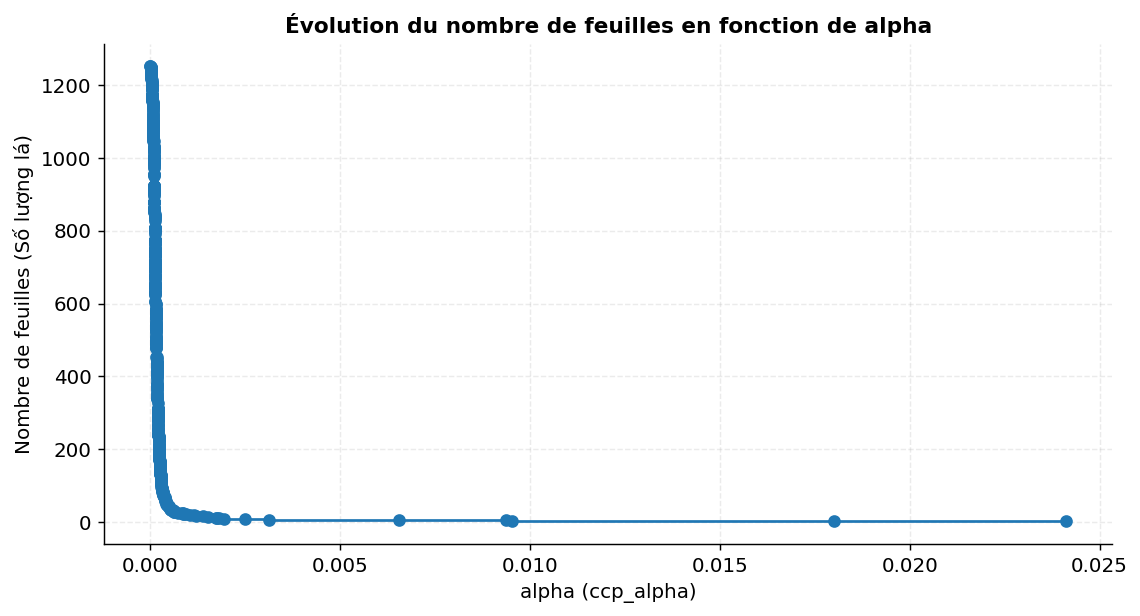

In [10]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# 1. Huấn luyện cây hoàn chỉnh (complet)
complet = DecisionTreeClassifier(random_state=42)
complet.fit(X_train, y_train)

# 2. Lấy đường dẫn cắt tỉa CCP và danh sách alpha
chemin = complet.cost_complexity_pruning_path(X_train, y_train)
alphas = chemin.ccp_alphas[:-1]  # Bỏ giá trị alpha lớn nhất (cây chỉ còn 1 nút gốc)

# 3. Xây dựng danh sách các cây tương ứng với từng alpha
clfs = []
for alpha in alphas:
  # Tạo cây với ccp_alpha tương ứng
  clf = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
  clf.fit(X_train, y_train)
  clfs.append(clf)

print(f'Tổng số lượng cây được tạo ra tương ứng với các alpha: {len(clfs)}')

# 4. Kiểm tra số lượng lá theo từng alpha
node_counts = [clf.tree_.node_count for clf in clfs]
depths = [clf.get_depth() for clf in clfs]
leaf_counts = [clf.get_n_leaves() for clf in clfs]

# Trực quan hóa số lượng lá giảm dần theo alpha
plt.figure(figsize=(10, 5))
plt.plot(alphas, leaf_counts, marker='o', drawstyle='steps-post')
plt.xlabel('alpha (ccp_alpha)')
plt.ylabel('Nombre de feuilles (Số lượng lá)')
plt.title('Évolution du nombre de feuilles en fonction de alpha')
plt.grid(True)
plt.show()

### 3.2 Choisir alpha

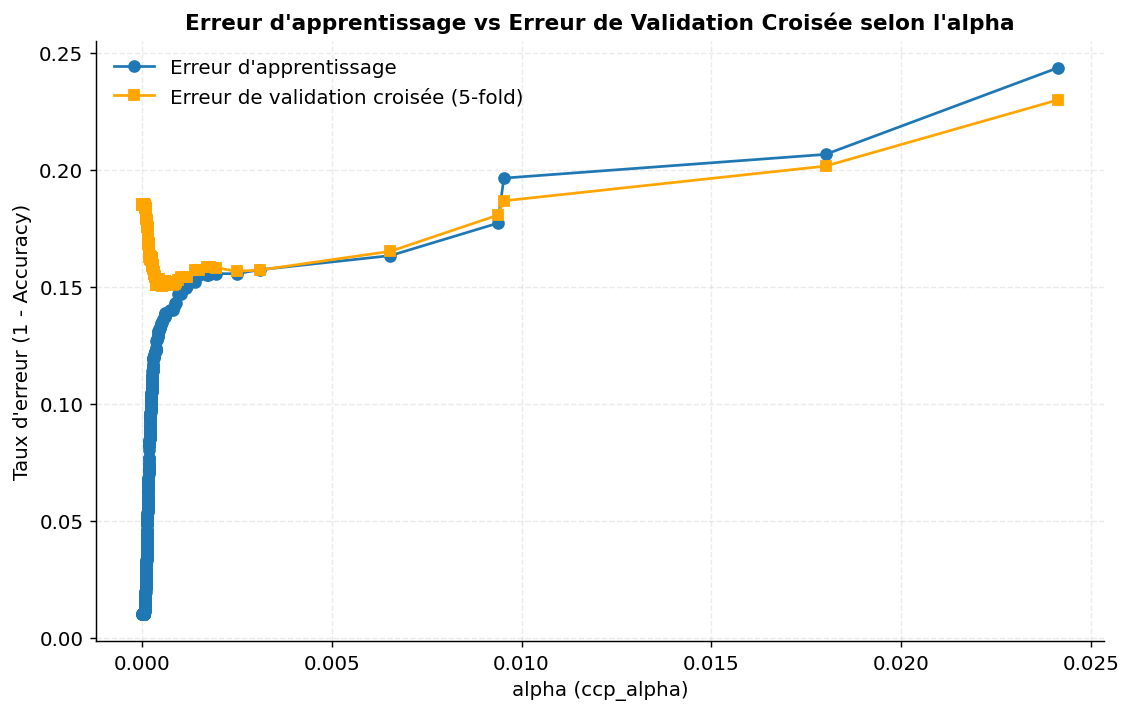

==> Meilleurs alpha retenu par validation croisée : 0.0005409387831280376
==> Erreur de test de l’arbre retenu : 0.1473


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

# 1. Khởi tạo K-fold phân tầng (5 plis)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_errors = []
cv_errors = []

# 2. Vòng lặp tính toán lỗi cho từng alpha
for alpha in alphas:
  # Khởi tạo mô hình với ccp_alpha tương ứng
  clf = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)

  # A. Tính lỗi học (sur l'apprentissage complet)
  clf.fit(X_train, y_train)
  train_err = 1 - accuracy_score(y_train, clf.predict(X_train))
  train_errors.append(train_err)

  # B. Tính lỗi validation croisée 5 plis (sur l'apprentissage seul)
  # cross_val_score trả về danh sách các accuracy trên từng fold
  cv_scores = cross_val_score(
      clf, X_train, y_train, cv=cv_strategy, scoring='accuracy'
  )
  cv_err = 1 - cv_scores.mean()
  cv_errors.append(cv_err)

# 3. Tracé des courbes (Vẽ đồ thị)
plt.figure(figsize=(10, 6))
plt.plot(alphas, train_errors, label="Erreur d'apprentissage", marker='o')
plt.plot(
    alphas,
    cv_errors,
    label='Erreur de validation croisée (5-fold)',
    marker='s',
    color='orange',
)
plt.xlabel('alpha (ccp_alpha)')
plt.ylabel("Taux d'erreur (1 - Accuracy)")
plt.title(
    "Erreur d'apprentissage vs Erreur de Validation Croisée selon l'alpha"
)
plt.legend()
plt.grid(True)
plt.show()

# 4. Retenir le meilleur alpha (minimisant l'erreur de validation croisée)
best_alpha_idx = np.argmin(cv_errors)
best_alpha = alphas[best_alpha_idx]
print(f'==> Meilleurs alpha retenu par validation croisée : {best_alpha}')

# 5. Erreur de test de l'arbre retenu — une seule fois
# Huấn luyện lại mô hình tốt nhất trên toàn bộ tập train
best_tree = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
best_tree.fit(X_train, y_train)

# Đánh giá trên tập test độc lập (chỉ làm 1 lần duy nhất)
test_error = 1 - accuracy_score(y_test, best_tree.predict(X_test))
print(f'==> Erreur de test de l’arbre retenu : {test_error:.4f}')


### 3.3 La règle du 1 écart-type

In [12]:
import numpy as np

cv_mean_errors = []
cv_se_errors = []

for alpha in alphas:
  clf = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
  # Utiliser cross_val_score pour récupérer les scores sur les 5 plis
  scores = cross_val_score(
      clf, X_train, y_train, cv=cv_strategy, scoring='accuracy'
  )
  errors = 1 - scores

  cv_mean_errors.append(errors.mean())
  # Erreur standard (SE) = écart-type / racine carrée du nombre de plis (ici 5)
  cv_se_errors.append(errors.std() / np.sqrt(5))

# 1. Trouver le minimum strict
min_idx = np.argmin(cv_mean_errors)
min_err = cv_mean_errors[min_idx]
min_se = cv_se_errors[min_idx]

# Seuil de Breiman (min + 1 * SE)
threshold = min_err + min_se

# 2. Trouver l'arbre le plus simple (alpha le plus grand / le moins de feuilles)
# dont l'erreur reste en dessous du seuil
valid_indices = [i for i, err in enumerate(cv_mean_errors) if err <= threshold]
# L'arbre le plus simple est celui avec l'indice le plus grand parmi les valides
breiman_idx = max(valid_indices)
best_alpha_breiman = alphas[breiman_idx]

print(f"Alpha min strict : {alphas[min_idx]}")
print(f"Alpha règle de Breiman : {best_alpha_breiman}")

# 3. Comparaison des feuilles et du test
tree_strict = DecisionTreeClassifier(
    random_state=42, ccp_alpha=alphas[min_idx]
).fit(X_train, y_train)
tree_breiman = DecisionTreeClassifier(
    random_state=42, ccp_alpha=best_alpha_breiman
).fit(X_train, y_train)

leaves_strict = tree_strict.get_n_leaves()
leaves_breiman = tree_breiman.get_n_leaves()

test_err_strict = 1 - accuracy_score(y_test, tree_strict.predict(X_test))
test_err_breiman = 1 - accuracy_score(y_test, tree_breiman.predict(X_test))

print(
    f'Feuilles (Min strict) : {leaves_strict} | Feuilles (Breiman) :'
    f' {leaves_breiman}'
)
print(
    f'Feuilles gagnées (économisées) : {leaves_strict - leaves_breiman}'
)
print(
    f'Erreur test (Min strict) : {test_err_strict:.4f} | Erreur test (Breiman) :'
    f' {test_err_breiman:.4f}'
)
print(f'Différence sur le test : {test_err_breiman - test_err_strict:.4f}')

Alpha min strict : 0.0005409387831280376
Alpha règle de Breiman : 0.0008685618700412581
Feuilles (Min strict) : 34 | Feuilles (Breiman) : 23
Feuilles gagnées (économisées) : 11
Erreur test (Min strict) : 0.1473 | Erreur test (Breiman) : 0.1517
Différence sur le test : 0.0043


## Exercice 4 — Importance des variables

In [13]:
import pandas as pd

# 1. Extraire les importances de l'arbre élagué (ex: best_tree ou tree_breiman)
importances = best_tree.feature_importances_
feature_names = X_train.columns  # Les colonnes après One-Hot Encoding

# 2. Créer un DataFrame pour associer chaque variable à son importance et trier par ordre décroissant
df_importances = pd.DataFrame(
    {'Variable': feature_names, 'Importance': importances}
)
df_importances = df_importances.sort_values(by='Importance', ascending=False)

# 3. Afficher le top des variables les plus importantes
print(df_importances.head(15))

                             Variable  Importance
27  marital-status_Married-civ-spouse    0.418784
1                        capital-gain    0.246604
0                                 age    0.059024
19                education_Bachelors    0.055001
40          occupation_Prof-specialty    0.054057
2                        capital-loss    0.046985
34         occupation_Exec-managerial    0.037754
3                      hours-per-week    0.022090
22                  education_Masters    0.016355
35         occupation_Farming-fishing    0.008387
25             education_Some-college    0.007597
20                education_Doctorate    0.005174
91       native-country_United-States    0.004769
43            occupation_Tech-support    0.003647
45         relationship_Not-in-family    0.003577


cộng tổng hết tất cả cái này lại sẽ được 1. Cái này in ra mức độ quan trọng của từng biến variable. Có thể thấy là cái biến quan trọng nhất đó là marial-status_Married-civ-spouse 

Mô hình cây quyết định của bạn đang dựa chủ yếu vào tình trạng hôn nhân và lợi nhuận vốn để đưa ra hơn 66% quyết định phân loại thu nhập, sau đó mới xét đến các yếu tố phụ trợ như tuổi tác, học vấn và loại nghề nghiệp.